<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%969.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import math
import random
import time

import numpy as np
import pandas as pd
import torch
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

matplotlib.rcParams['figure.figsize'] = (10.0, 5.0)

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Завдання 1. Модель LeNet5 на MNIST

> Реалізуйте модель наведену у теоретичній частині, натренуйте та проаналізуйте результат та швидкість навчання (для довідки, найкращі результати на наборі даних MNIST мають похибку 0.03% тобто точність більше ніж 99.97)

## Дані MNIST

60000 10000


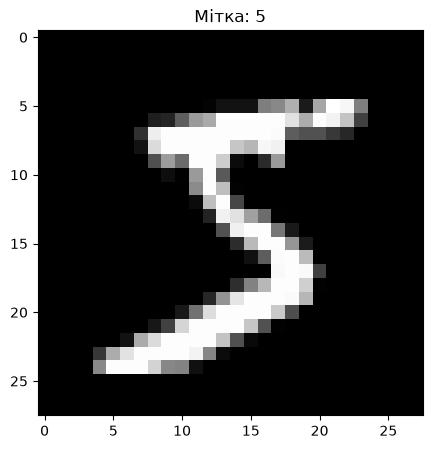

torch.Size([60000, 1, 28, 28])


In [ ]:
MNIST_train = torchvision.datasets.MNIST('./', download=True, train=True)
MNIST_test = torchvision.datasets.MNIST('./', download=True, train=False)

X_train = MNIST_train.data
y_train = MNIST_train.targets
X_test = MNIST_test.data
y_test = MNIST_test.targets

print(len(y_train), len(y_test))

plt.imshow(X_train[0, :, :], cmap='gray')
plt.title(f'Мітка: {y_train[0].item()}')
plt.show()

X_train = X_train.unsqueeze(1).float()
X_test = X_test.unsqueeze(1).float()

print(X_train.shape)

Картинка має розмір 28 на 28 і один канал, тому в згорткову мережу її передають як тензор `1 × 28 × 28`. Для цього до кожного зображення додається розмірність каналів через `unsqueeze(1)`.

In [ ]:
pixel_mean = X_train.mean() / 255.
pixel_std = X_train.std() / 255.

X_train = ((X_train / 255.) - pixel_mean) / pixel_std
X_test = ((X_test / 255.) - pixel_mean) / pixel_std

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_train), generator=generator)
val_idx, train_idx = permutation[:10000], permutation[10000:]

X_val, y_val = X_train[val_idx].to(device), y_train[val_idx].to(device)
X_train, y_train = X_train[train_idx].to(device), y_train[train_idx].to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

print(X_train.shape, X_val.shape, X_test.shape)
print("mean/std пікселів:", round(pixel_mean.item(), 4), round(pixel_std.item(), 4))

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])
mean/std пікселів: 0.1307 0.3081


Значення пікселів нормуються: ділення на 255 і віднімання середнього зі зведенням до одиничного стандартного відхилення. З 60 000 тренувальних зображень випадково відокремлюється 10 000 для валідації, а 10 000 офіційних тестових лишаються для фінальної оцінки.

## Модель LeNet5

In [ ]:
class LeNet5(torch.nn.Module):
    def __init__(self, in_channels=1, conv1_padding=2, extra_conv=False, extra_fc=False):
        super(LeNet5, self).__init__()

        self.conv1 = torch.nn.Conv2d(
            in_channels=in_channels, out_channels=6, kernel_size=5, padding=conv1_padding)
        self.act1 = torch.nn.Tanh()
        self.pool1 = torch.nn.AvgPool2d(kernel_size=2, stride=2)

        self.extra_conv = None
        if extra_conv:
            self.extra_conv = torch.nn.Sequential(
                torch.nn.Conv2d(6, 6, kernel_size=5, padding=2), torch.nn.Tanh())

        self.conv2 = torch.nn.Conv2d(
            in_channels=6, out_channels=16, kernel_size=5, padding=0)
        self.act2 = torch.nn.Tanh()
        self.pool2 = torch.nn.AvgPool2d(kernel_size=2, stride=2)

        self.fc1 = torch.nn.Linear(5 * 5 * 16, 120)
        self.act3 = torch.nn.Tanh()
        self.fc2 = torch.nn.Linear(120, 84)
        self.act4 = torch.nn.Tanh()

        self.extra_fc = None
        if extra_fc:
            self.extra_fc = torch.nn.Sequential(torch.nn.Linear(84, 84), torch.nn.Tanh())

        self.fc3 = torch.nn.Linear(84, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.act1(x)
        x = self.pool1(x)

        if self.extra_conv is not None:
            x = self.extra_conv(x)

        x = self.conv2(x)
        x = self.act2(x)
        x = self.pool2(x)

        x = x.view(x.size(0), x.size(1) * x.size(2) * x.size(3))

        x = self.fc1(x)
        x = self.act3(x)
        x = self.fc2(x)
        x = self.act4(x)

        if self.extra_fc is not None:
            x = self.extra_fc(x)

        x = self.fc3(x)
        return x

lenet5 = LeNet5().to(device)
print(lenet5)
print("Кількість параметрів:", sum(p.numel() for p in lenet5.parameters()))

with torch.no_grad():
    probe = X_train[:2]
    x = lenet5.pool1(lenet5.act1(lenet5.conv1(probe)))
    print("після conv1 + pool1:", tuple(x.shape))
    x = lenet5.pool2(lenet5.act2(lenet5.conv2(x)))
    print("після conv2 + pool2:", tuple(x.shape))

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (act1): Tanh()
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (act2): Tanh()
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (act3): Tanh()
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (act4): Tanh()
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Кількість параметрів: 61706
після conv1 + pool1: (2, 6, 14, 14)
після conv2 + pool2: (2, 16, 5, 5)


Перший згортковий шар має 6 каналів і ядро 5 на 5 з відступом (padding) 2, тому розмір 28 на 28 зберігається, а пулінг стискає його до 14 на 14. Другий шар має 16 каналів без відступу, тому з 14 на 14 виходить 10 на 10, а пулінг дає 5 на 5. Тензор 5 × 5 × 16 = 400 розтягується в вектор і проходить три повнозв'язні шари (400 → 120 → 84 → 10).

## Навчання

In [ ]:
def evaluate(model, X, y, batch=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for start in range(0, len(X), batch):
            outputs = model(X[start:start + batch])
            total_loss += torch.nn.functional.cross_entropy(outputs, y[start:start + batch], reduction='sum').item()
            correct += (outputs.argmax(dim=1) == y[start:start + batch]).sum().item()
    model.train()
    return total_loss / len(X), correct / len(X)

def random_shift(x, max_shift=2):
    dx, dy = torch.randint(-max_shift, max_shift + 1, (2,)).tolist()
    return torch.roll(x, shifts=(dy, dx), dims=(2, 3))

def train_net(model, epochs, X_tr=None, y_tr=None, X_va=None, y_va=None, lr=1e-3, batch_size=100,
              seed=0, augment=False, cosine=False):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs) if cosine else None
    loss_fn = torch.nn.CrossEntropyLoss()
    order_generator = torch.Generator().manual_seed(seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}

    for epoch in range(epochs):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start_time = time.perf_counter()

        model.train()
        order = torch.randperm(len(X_tr), generator=order_generator).to(X_tr.device)
        running_loss = 0.0

        for start_index in range(0, len(X_tr), batch_size):
            optimizer.zero_grad()

            batch_indexes = order[start_index:start_index + batch_size]
            X_batch = X_tr[batch_indexes]
            y_batch = y_tr[batch_indexes]
            if augment:
                X_batch = random_shift(X_batch)

            preds = model.forward(X_batch)
            loss_value = loss_fn(preds, y_batch)
            loss_value.backward()

            optimizer.step()
            running_loss += loss_value.item() * len(batch_indexes)

        if scheduler is not None:
            scheduler.step()

        if device.type == 'cuda':
            torch.cuda.synchronize()
        history['epoch_time'].append(time.perf_counter() - start_time)

        val_loss, val_acc = evaluate(model, X_va, y_va)
        history['train_loss'].append(running_loss / len(X_tr))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    return history

Навчання йде батчами по 100 зображень з оптимізатором Adam зі швидкістю 1e-3 і функцією втрат крос-ентропії, як у теорії. Після кожної епохи рахуються втрата та точність на валідації, а також вимірюється час епохи.

In [ ]:
torch.manual_seed(0)
lenet5 = LeNet5().to(device)
lenet_history = train_net(lenet5, epochs=20)

test_loss, test_acc = evaluate(lenet5, X_test, y_test)

rows = []
for epoch in (1, 2, 5, 10, 15, 20):
    rows.append({
        'епоха': epoch,
        'train loss': lenet_history['train_loss'][epoch - 1],
        'val loss': lenet_history['val_loss'][epoch - 1],
        'val accuracy': lenet_history['val_acc'][epoch - 1],
    })
print(pd.DataFrame(rows).set_index('епоха').round(4).to_string())

print("Найкраща validation accuracy:", round(max(lenet_history['val_acc']), 4),
      "на епосі", int(np.argmax(lenet_history['val_acc'])) + 1)
print("Test accuracy після 20 епох:", round(test_acc, 4), "| test loss:", round(test_loss, 4))
print("Середній час епохи, с:", round(np.mean(lenet_history['epoch_time']), 2))

       train loss  val loss  val accuracy
епоха                                    
1          0.3396    0.1342        0.9604
2          0.0920    0.0815        0.9756
5          0.0365    0.0546        0.9831
10         0.0150    0.0683        0.9803
15         0.0088    0.0531        0.9861
20         0.0086    0.0611        0.9860
Найкраща validation accuracy: 0.9862 на епосі 14
Test accuracy після 20 епох: 0.9868 | test loss: 0.0532
Середній час епохи, с: 5.88


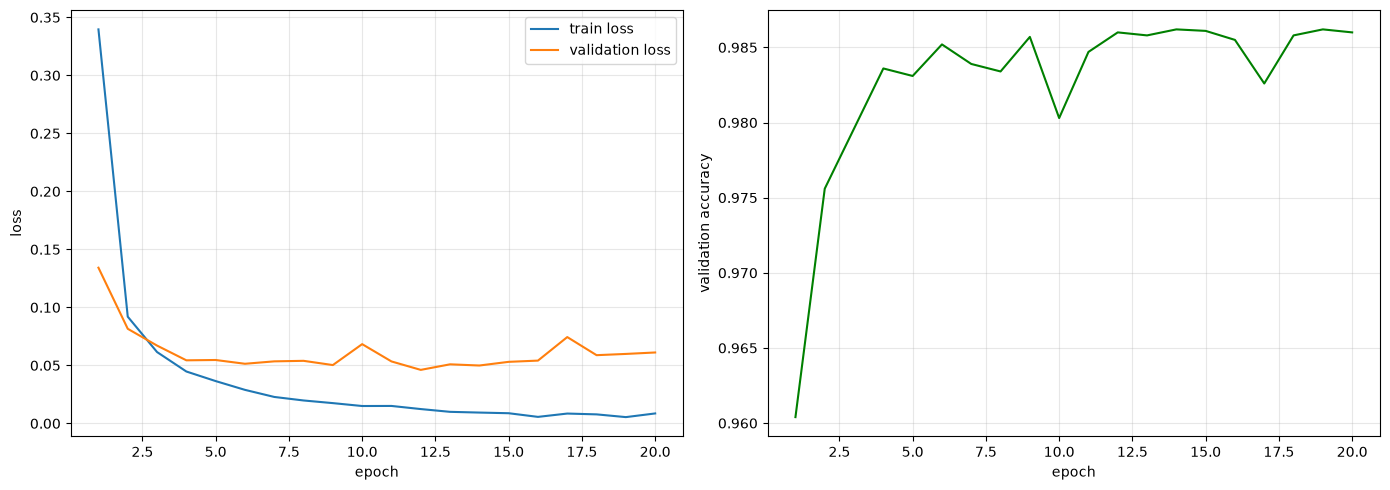

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, 21), lenet_history['train_loss'], label='train loss')
axes[0].plot(range(1, 21), lenet_history['val_loss'], label='validation loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(range(1, 21), lenet_history['val_acc'], color='g')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('validation accuracy')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
class FCBaseline(torch.nn.Module):
    def __init__(self):
        super(FCBaseline, self).__init__()
        self.fc1 = torch.nn.Linear(28 * 28, 100)
        self.ac1 = torch.nn.Sigmoid()
        self.fc2 = torch.nn.Linear(100, 10)

    def forward(self, x):
        return self.fc2(self.ac1(self.fc1(x.reshape(len(x), -1))))

torch.manual_seed(0)
fc_net = FCBaseline().to(device)
fc_history = train_net(fc_net, epochs=3)
_, fc_acc = evaluate(fc_net, X_test, y_test)

print("Повнозв'язна мережа 784-100-10: час епохи", round(np.mean(fc_history['epoch_time']), 2), "с, параметрів",
      sum(p.numel() for p in fc_net.parameters()))
print("LeNet5:", "час епохи", round(np.mean(lenet_history['epoch_time']), 2), "с, параметрів",
      sum(p.numel() for p in lenet5.parameters()))

Повнозв'язна мережа 784-100-10: час епохи 0.24 с, параметрів 79510
LeNet5: час епохи 5.88 с, параметрів 61706


**Результат і швидкість навчання.** LeNet5 має 61 706 параметрів і за 20 епох досягає найкращої точності на валідації 0.9862 (епоха 14), а на тесті 0.9868. Точність швидко росте на початку (0.960 після першої епохи, 0.983 після п'ятої), після чого виходить на плато близько 0.986. Це краще за повнозв'язну мережу з попередньої роботи (близько 0.975), але далеко від найкращих результатів на MNIST, де похибка становить 0.03%: у LeNet5 похибка близько 1.3%.

Втрата на тренуванні продовжує падати (0.0086 на 20-й епосі), а на валідації мінімум 0.046 досягається на 12-й епосі, після чого вона трохи зростає до 0.061. Тобто з'являється помірне перенавчання, хоча точність на валідації не падає.

Навчання LeNet5 відбувається значно повільніше, ніж повнозв'язної мережі: близько 5.9 с на епоху проти 0.24 с у мережі 784-100-10 (приблизно в 24 рази), хоча параметрів у LeNet5 менше (61 706 проти 79 510). Причина в тому, що кожне згорткове ядро застосовується до кожної позиції зображення, тому кількість обчислень значно перевищує кількість параметрів.

# Завдання 2. Якість 0.992 на MNIST

> Спробуйте домогтися якості 0.992 на даному наборі даних (в максимумі на валідації). Зверніть увагу на наступні моменти:
>
> a. Чи з'являється перенавчання при збільшенні кількості епох?
>
> b. Як додавання різних шарів впливає на швидкість навчання (які шари обробляються швидше: згорткові або повнозв'язні)?
>
> c. Проаналізуйте дисперсію цільової метрики від запуску до запуску.
>
> d. Скільки запусків досить зробити, перед тим як стверджувати, що одна архітектура краща за іншу?

## Покращена згорткова мережа

In [ ]:
class ImprovedCNN(torch.nn.Module):
    def __init__(self, c1=16, c2=32, dropout=0.3):
        super(ImprovedCNN, self).__init__()
        self.features = torch.nn.Sequential(
            torch.nn.Conv2d(1, c1, kernel_size=3, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(2),
            torch.nn.Conv2d(c1, c2, kernel_size=3, padding=1),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(2),
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(c2 * 7 * 7, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
improved = ImprovedCNN().to(device)
print(improved)
print("Кількість параметрів:", sum(p.numel() for p in improved.parameters()))

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=1568, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Кількість параметрів: 206922


Щоб досягти 0.992, до LeNet5 внесено кілька змін:
- активація ReLU замість Tanh та max pooling замість average pooling;
- ядра 3 на 3 і більше каналів (16 та 32);
- dropout 0.3 перед повнозв'язним шаром проти перенавчання;
- аугментація: до кожного батча застосовується випадковий зсув зображення до 2 пікселів;
- косинусне зменшення швидкості навчання до кінця тренування.

In [ ]:
torch.manual_seed(0)
improved = ImprovedCNN().to(device)
improved_history = train_net(improved, epochs=20, augment=True, cosine=True)

best_val = max(improved_history['val_acc'])
best_epoch = int(np.argmax(improved_history['val_acc'])) + 1
test_loss_i, test_acc_i = evaluate(improved, X_test, y_test)

print("Validation accuracy за епохами:", [round(a, 4) for a in improved_history['val_acc']])
print("Максимум validation accuracy:", round(best_val, 4), "на епосі", best_epoch)
print("Ціль 0.992 досягнуто:", best_val >= 0.992)
print("Test accuracy після 20 епох:", round(test_acc_i, 4))
print("Середній час епохи, с:", round(np.mean(improved_history['epoch_time']), 2))

Validation accuracy за епохами: [0.9749, 0.9819, 0.9846, 0.9873, 0.9881, 0.9896, 0.99, 0.9912, 0.9908, 0.9899, 0.9916, 0.9923, 0.9918, 0.992, 0.9926, 0.9923, 0.9924, 0.9925, 0.9925, 0.9926]
Максимум validation accuracy: 0.9926 на епосі 15
Ціль 0.992 досягнуто: True
Test accuracy після 20 епох: 0.9941
Середній час епохи, с: 6.94


**Результат.** Покращена мережа має 206 922 параметри і досягає максимальної точності на валідації 0.9926 (епоха 15), тобто ціль 0.992 виконана. Вперше 0.992 досягається на 12-й епосі, а наприкінці 20 епох точність тримається на рівні 0.9925–0.9926. На тесті мережа дає 0.9941 (похибка близько 0.6% проти 1.3% у LeNet5). Час епохи становить близько 6.9 с, тобто лишається близьким до LeNet5. Внесок кожної окремої зміни окремо не вимірювався, результат отримано їх комбінацією.

# Завдання 2a. Перенавчання при збільшенні кількості епох

> a. Чи з'являється перенавчання при збільшенні кількості епох?

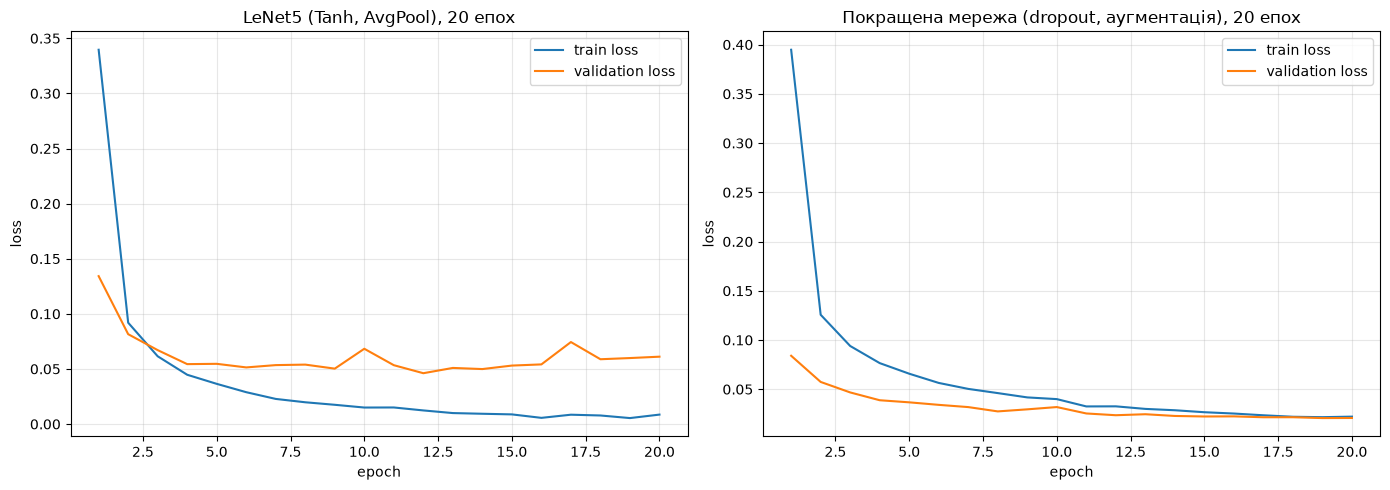

LeNet5: мінімум val loss 0.0461 на епосі 12, val loss на епосі 20 = 0.0611, train loss на епосі 20 = 0.0086
Покращена: мінімум val loss 0.0207 на епосі 19, val loss на епосі 20 = 0.0208, train loss на епосі 20 = 0.0222


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, history, title in ((axes[0], lenet_history, 'LeNet5 (Tanh, AvgPool), 20 епох'),
                           (axes[1], improved_history, 'Покращена мережа (dropout, аугментація), 20 епох')):
    ax.plot(range(1, 21), history['train_loss'], label='train loss')
    ax.plot(range(1, 21), history['val_loss'], label='validation loss')
    ax.set_title(title)
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

for name, history in (('LeNet5', lenet_history), ('Покращена', improved_history)):
    best_loss_epoch = int(np.argmin(history['val_loss'])) + 1
    print(f"{name}: мінімум val loss {min(history['val_loss']):.4f} на епосі {best_loss_epoch}, "
          f"val loss на епосі 20 = {history['val_loss'][-1]:.4f}, train loss на епосі 20 = {history['train_loss'][-1]:.4f}")

**Відповідь.** У LeNet5 перенавчання з'являється, але помірне. Втрата на тренуванні продовжує падати (з 0.34 на першій епосі до 0.0086 на 20-й), а втрата на валідації мінімальна (0.0461) на 12-й епосі й надалі зростає до 0.061. Точність на валідації при цьому не падає, а залишається близько 0.986, тобто мережа дедалі впевненіше помиляється на тих прикладах, які класифікує неправильно. У покращеній мережі перенавчання немає: втрата на валідації продовжує зменшуватись до 19-ї епохи (мінімум 0.0207), а на 20-й епосі дорівнює 0.0208 і не перевищує втрату на тренуванні (0.0222, яка рахується з увімкненими dropout і зсувами). Цього вдалося досягти завдяки dropout, аугментації та зменшенню швидкості навчання.

# Завдання 2b. Швидкість згорткових і повнозв'язних шарів

> b. Як додавання різних шарів впливає на швидкість навчання (які шари обробляються швидше: згорткові або повнозв'язні)?

In [ ]:
def time_layer(layer, input_shape, repeats=100):
    x = torch.randn(*input_shape, device=device, requires_grad=True)
    layer = layer.to(device)
    for _ in range(5):
        layer(x).sum().backward()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        layer(x).sum().backward()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / repeats * 1000

torch.manual_seed(0)
reference = LeNet5()
layers = [
    ('conv1: 1 -> 6, 5x5', reference.conv1, (100, 1, 28, 28)),
    ('pool1: AvgPool 2x2', reference.pool1, (100, 6, 28, 28)),
    ('conv2: 6 -> 16, 5x5', reference.conv2, (100, 6, 14, 14)),
    ('pool2: AvgPool 2x2', reference.pool2, (100, 16, 10, 10)),
    ('fc1: 400 -> 120', reference.fc1, (100, 400)),
    ('fc2: 120 -> 84', reference.fc2, (100, 120)),
    ('fc3: 84 -> 10', reference.fc3, (100, 84)),
]

rows = []
for name, layer, shape in layers:
    params = sum(p.numel() for p in layer.parameters())
    rows.append({'шар': name, 'параметрів': params, 'час, мс (вперед + назад, батч 100)': time_layer(layer, shape)})

layer_table = pd.DataFrame(rows).set_index('шар')
print(layer_table.round(3).to_string())

                     параметрів  час, мс (вперед + назад, батч 100)
шар                                                                
conv1: 1 -> 6, 5x5          156                               6.744
pool1: AvgPool 2x2            0                               0.396
conv2: 6 -> 16, 5x5        2416                               4.764
pool2: AvgPool 2x2            0                               0.227
fc1: 400 -> 120           48120                               0.133
fc2: 120 -> 84            10164                               0.058
fc3: 84 -> 10               850                               0.046


In [ ]:
def time_epoch_fraction(model, n_batches=100):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = torch.nn.CrossEntropyLoss()
    X_part, y_part = X_train[:100 * n_batches], y_train[:100 * n_batches]

    def run():
        for start in range(0, len(X_part), 100):
            optimizer.zero_grad()
            loss_fn(model(X_part[start:start + 100]), y_part[start:start + 100]).backward()
            optimizer.step()

    run()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start_time = time.perf_counter()
    run()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return (time.perf_counter() - start_time) / n_batches * 1000

rows = []
for label, kwargs in (('LeNet5 (2 згортки + 3 повнозв\'язні)', {}),
                      ('+ ще один згортковий шар', {'extra_conv': True}),
                      ('+ ще один повнозв\'язний шар', {'extra_fc': True}),
                      ('+ обидва додаткові шари', {'extra_conv': True, 'extra_fc': True})):
    torch.manual_seed(0)
    model = LeNet5(**kwargs)
    params = sum(p.numel() for p in model.parameters())
    rows.append({'архітектура': label, 'параметрів': params, 'мс на батч (навчання)': time_epoch_fraction(model)})

variants_table = pd.DataFrame(rows).set_index('архітектура')
base_ms = variants_table.iloc[0]['мс на батч (навчання)']
variants_table['відносно LeNet5'] = variants_table['мс на батч (навчання)'] / base_ms
print(variants_table.round(3).to_string())

                                     параметрів  мс на батч (навчання)  відносно LeNet5
архітектура                                                                            
LeNet5 (2 згортки + 3 повнозв'язні)       61706                 12.200            1.000
+ ще один згортковий шар                  62612                 19.312            1.583
+ ще один повнозв'язний шар               68846                 11.725            0.961
+ обидва додаткові шари                   69752                 19.298            1.582


**Відповідь.** Згорткові шари обробляються значно повільніше за повнозв'язні, хоча мають набагато менше параметрів. На CPU прохід вперед і назад на батчі з 100 зображень для conv1 (156 параметрів) займає 6.7 мс, для conv2 (2416 параметрів) 4.8 мс, а для fc1 (48 120 параметрів) лише 0.13 мс, для fc2 0.06 мс і для fc3 0.05 мс. Шари пулінгу займають 0.2–0.4 мс. Це відображається на навчанні всієї мережі: час на батч LeNet5 дорівнює 12.2 мс, додавання ще одного згорткового шару збільшує його приблизно в 1.6 раза (19.3 мс), а додавання ще одного повнозв'язного шару практично не змінює (11.7 мс, у межах похибки вимірювання). Отже, швидкість навчання визначають згорткові шари, а додавати повнозв'язні шари дешево. Виміри зроблено на CPU, на відеокарті абсолютні числа будуть іншими.

# Завдання 2c. Дисперсія метрики від запуску до запуску

> c. Проаналізуйте дисперсію цільової метрики від запуску до запуску.

In [ ]:
SEEDS = (0, 1, 2, 3, 4)
EPOCHS_RUNS = 10

runs = {'LeNet5': [], 'Покращена мережа': []}

for seed in SEEDS:
    torch.manual_seed(seed)
    net = LeNet5().to(device)
    history = train_net(net, epochs=EPOCHS_RUNS, seed=seed)
    runs['LeNet5'].append(max(history['val_acc']))

    torch.manual_seed(seed)
    net = ImprovedCNN().to(device)
    history = train_net(net, epochs=EPOCHS_RUNS, seed=seed, augment=True, cosine=True)
    runs['Покращена мережа'].append(max(history['val_acc']))

rows = []
for name, values in runs.items():
    values = np.array(values)
    rows.append({'архітектура': name, 'seed 0': values[0], 'seed 1': values[1], 'seed 2': values[2],
                 'seed 3': values[3], 'seed 4': values[4], 'середнє': values.mean(),
                 'std': values.std(ddof=1), 'розмах (макс - мін)': values.max() - values.min()})

variance_table = pd.DataFrame(rows).set_index('архітектура')
print(variance_table.round(4).to_string())

                  seed 0  seed 1  seed 2  seed 3  seed 4  середнє     std  розмах (макс - мін)
архітектура                                                                                   
LeNet5            0.9857  0.9870  0.9879  0.9858  0.9855   0.9864  0.0010               0.0024
Покращена мережа  0.9912  0.9911  0.9921  0.9906  0.9905   0.9911  0.0006               0.0016


**Відповідь.** Метрика змінюється від запуску до запуску навіть при тих самих налаштуваннях, змінюється лише початкова ініціалізація та порядок батчів. Для LeNet5 за п'ять запусків по 10 епох максимальна validation accuracy лежить у межах 0.9855–0.9879: середнє 0.9864, стандартне відхилення 0.0010, розмах 0.0024. У покращеної мережі 0.9905–0.9921: середнє 0.9911, стандартне відхилення 0.0006, розмах 0.0016. Тобто випадковий розкид становить близько 0.1 відсоткового пункту (розмах до 0.24 п.п.), що порівнянне з різницею між близькими архітектурами. Тому один запуск не дозволяє зробити висновок про кращу архітектуру, коли різниця мала. При цьому різниця між LeNet5 і покращеною мережею (0.0047) у кілька разів перевищує розкид, тому вона не випадкова. Зауважте, що за 10 епох покращена мережа ще не доходить до 0.992 (її косинусний графік швидкості навчання розрахований на 10 епох), на відміну від 20 епох в основному запуску.

# Завдання 2d. Скільки запусків потрібно

> d. Скільки запусків досить зробити, перед тим як стверджувати, що одна архітектура краща за іншу?

In [ ]:
a = np.array(runs['LeNet5'])
b = np.array(runs['Покращена мережа'])

rows = []
for n in range(2, len(SEEDS) + 1):
    t_stat, p_value = stats.ttest_ind(b[:n], a[:n], equal_var=False)
    rows.append({'запусків': n, 'різниця середніх': b[:n].mean() - a[:n].mean(), 't': t_stat, 'p-value': p_value})

print(pd.DataFrame(rows).set_index('запусків').round(5).to_string())

sigma = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
print()
print("Типовий розкид (std) між запусками:", round(sigma, 5))
print("Необхідна кількість запусків на кожну архітектуру (рівень значущості 5%, потужність 80%):")
for delta in (0.005, 0.002, 0.001, 0.0005):
    n_required = math.ceil(2 * (1.96 + 0.84) ** 2 * sigma ** 2 / delta ** 2)
    print(f"  якщо справжня різниця {delta:.4f}: {n_required}")

          різниця середніх        t  p-value
запусків                                    
2                  0.00480  7.36286  0.08411
3                  0.00460  6.44832  0.00809
4                  0.00465  7.61886  0.00068
5                  0.00472  8.69908  0.00007

Типовий розкид (std) між запусками: 0.00086
Необхідна кількість запусків на кожну архітектуру (рівень значущості 5%, потужність 80%):
  якщо справжня різниця 0.0050: 1
  якщо справжня різниця 0.0020: 3
  якщо справжня різниця 0.0010: 12
  якщо справжня різниця 0.0005: 47


**Відповідь.** Кількість запусків залежить від того, наскільки різниця між архітектурами перевищує розкид результатів між запусками. Для нашого порівняння (різниця середніх 0.0047, розкид 0.0009) двох запусків недостатньо (p-value 0.084), а вже трьох достатньо (p-value 0.008), чотири і п'ять запусків підтверджують висновок ще впевненіше (p-value 0.0007 і 0.00007). Загальне правило: потрібно приблизно `2 · (1.96 + 0.84)² · σ² / δ²` запусків на кожну архітектуру (рівень значущості 5%, потужність 80%), де σ це розкид, а δ різниця, яку потрібно виявити. З виміряним розкидом 0.00086 це 1 запуск для різниці 0.005, 3 запуски для 0.002, 12 запусків для 0.001 і 47 запусків для 0.0005. Тобто для помітної різниці досить 3–5 запусків, а для різниць у десяті частки відсотка потрібні десятки запусків.

# Завдання 3. LeNet для набору даних CIFAR 10

> Спробуйте провести аналогічні розрахунки для набору даних CIFAR10:
>
> a. Змініть мережу LeNet таким чином, щоб вона приймала зображення 32 на 32 і три канали на вході. Щоб передати їй три канали, потрібно в in_chanels першої ж згортки поставити "3" (раніше тут було "1"). А ось розмірність 32 на 32 у нас виходить з паддінга. Як ви пам'ятаєте, в оригінальному LeNet була розмірність 32 на 32 і там були нульові паддінги, тобто згортка не виходили за зображення. Ми навмисно в LeNet для набору даних MNIST це змінювали, щоб у нас перша згортка виходила за зображення і після першої згортки було 28 на 28. А тепер ми, навпаки, хочемо щоб паддінга не було, і з розмірності 32 на 32 виходила розмірність 28 на 28. Відповідно, необхідно поставити паддінг "0". Більше нічого не змінюється – процес навчання не змінюється, він залишається таким же, як і раніше.
>
> b. Знайдіть оптимальну кількість епох для навчання, аналізуючи графіки втрат

In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

Xc_train = torch.from_numpy(CIFAR_train.data).float() / 255.
yc_train = torch.tensor(CIFAR_train.targets)
Xc_test = torch.from_numpy(CIFAR_test.data).float() / 255.
yc_test = torch.tensor(CIFAR_test.targets)

Xc_train = Xc_train.permute(0, 3, 1, 2)
Xc_test = Xc_test.permute(0, 3, 1, 2)

channel_mean = Xc_train.mean(dim=(0, 2, 3), keepdim=True)
channel_std = Xc_train.std(dim=(0, 2, 3), keepdim=True)
Xc_train = (Xc_train - channel_mean) / channel_std
Xc_test = (Xc_test - channel_mean) / channel_std

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(Xc_train), generator=generator)
val_idx_c, train_idx_c = permutation[:5000], permutation[5000:]

Xc_val, yc_val = Xc_train[val_idx_c].to(device), yc_train[val_idx_c].to(device)
Xc_tr, yc_tr = Xc_train[train_idx_c].to(device), yc_train[train_idx_c].to(device)
Xc_test, yc_test = Xc_test.to(device), yc_test.to(device)

print(CIFAR_train.classes)
print(Xc_tr.shape, Xc_val.shape, Xc_test.shape)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


Зображення CIFAR 10 мають розмір 32 на 32 з трьома каналами, значення пікселів нормуються по каналах, а розмірності переставляються на формат `кількість × канали × висота × ширина`. З 50 000 тренувальних зображень 5000 відводиться на валідацію.

In [ ]:
torch.manual_seed(0)
lenet_cifar = LeNet5(in_channels=3, conv1_padding=0).to(device)
print(lenet_cifar)

with torch.no_grad():
    probe = Xc_tr[:2]
    x = lenet_cifar.pool1(lenet_cifar.act1(lenet_cifar.conv1(probe)))
    print("після conv1 + pool1:", tuple(x.shape))
    x = lenet_cifar.pool2(lenet_cifar.act2(lenet_cifar.conv2(x)))
    print("після conv2 + pool2:", tuple(x.shape))

print("Кількість параметрів:", sum(p.numel() for p in lenet_cifar.parameters()))

LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (act1): Tanh()
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (act2): Tanh()
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (act3): Tanh()
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (act4): Tanh()
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
після conv1 + pool1: (2, 6, 14, 14)
після conv2 + pool2: (2, 16, 5, 5)
Кількість параметрів: 62006


Для зображень 32 на 32 перший згортковий шар отримує три вхідні канали і працює без відступу (`padding=0`): розмір 32 зменшується до 28, після пулінгу 14, після другої згортки 10, після другого пулінгу 5. Тож вектор перед повнозв'язними шарами, як і раніше, має розмір 5 × 5 × 16 = 400, і решта мережі не змінюється.

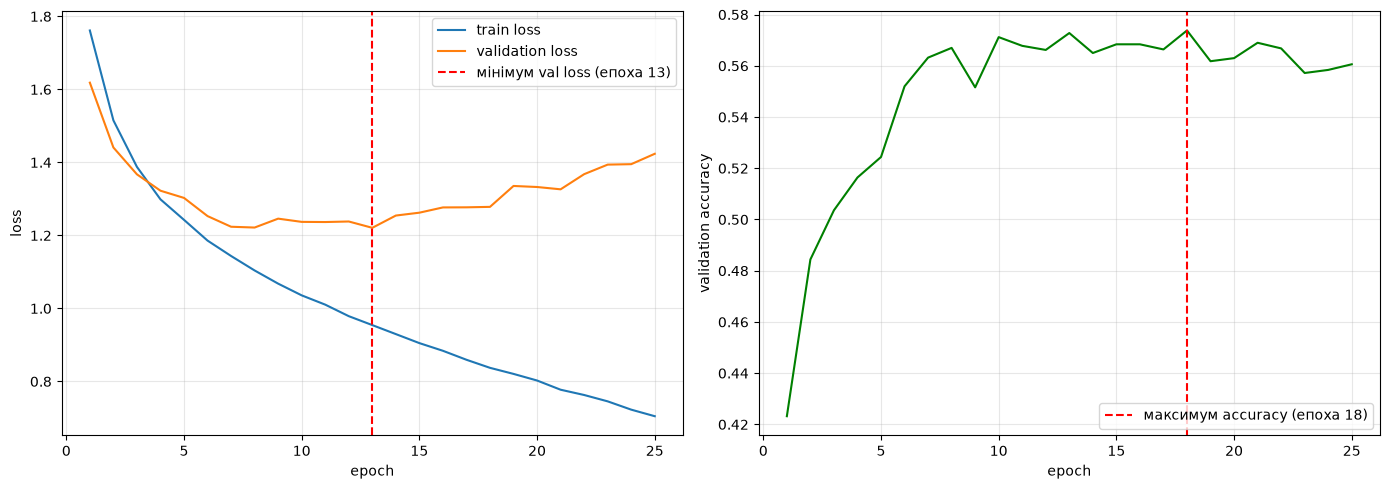

Мінімум validation loss: 1.2208 на епосі 13
Максимум validation accuracy: 0.5738 на епосі 18
Train loss на епосі 25 : 0.7047
Validation loss на епосі 25 : 1.4236
Середній час епохи, с: 6.02


In [ ]:
EPOCHS_CIFAR = 25

torch.manual_seed(0)
lenet_cifar = LeNet5(in_channels=3, conv1_padding=0).to(device)
cifar_history = train_net(lenet_cifar, epochs=EPOCHS_CIFAR, X_tr=Xc_tr, y_tr=yc_tr, X_va=Xc_val, y_va=yc_val)

best_epoch_loss = int(np.argmin(cifar_history['val_loss'])) + 1
best_epoch_acc = int(np.argmax(cifar_history['val_acc'])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, EPOCHS_CIFAR + 1), cifar_history['train_loss'], label='train loss')
axes[0].plot(range(1, EPOCHS_CIFAR + 1), cifar_history['val_loss'], label='validation loss')
axes[0].axvline(best_epoch_loss, color='r', linestyle='--', label=f'мінімум val loss (епоха {best_epoch_loss})')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(range(1, EPOCHS_CIFAR + 1), cifar_history['val_acc'], color='g')
axes[1].axvline(best_epoch_acc, color='r', linestyle='--', label=f'максимум accuracy (епоха {best_epoch_acc})')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('validation accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Мінімум validation loss:", round(min(cifar_history['val_loss']), 4), "на епосі", best_epoch_loss)
print("Максимум validation accuracy:", round(max(cifar_history['val_acc']), 4), "на епосі", best_epoch_acc)
print("Train loss на епосі", EPOCHS_CIFAR, ":", round(cifar_history['train_loss'][-1], 4))
print("Validation loss на епосі", EPOCHS_CIFAR, ":", round(cifar_history['val_loss'][-1], 4))
print("Середній час епохи, с:", round(np.mean(cifar_history['epoch_time']), 2))

In [ ]:
torch.manual_seed(0)
lenet_cifar_best = LeNet5(in_channels=3, conv1_padding=0).to(device)
train_net(lenet_cifar_best, epochs=best_epoch_loss, X_tr=Xc_tr, y_tr=yc_tr, X_va=Xc_val, y_va=yc_val)

test_loss_c, test_acc_c = evaluate(lenet_cifar_best, Xc_test, yc_test)
print(f"LeNet5 після {best_epoch_loss} епох: test loss = {test_loss_c:.4f}, test accuracy = {test_acc_c:.4f}")

with torch.no_grad():
    cifar_pred = lenet_cifar_best(Xc_test).argmax(dim=1)

per_class = pd.Series({
    CIFAR_train.classes[i]: (cifar_pred[yc_test == i] == i).float().mean().item() for i in range(10)
}).sort_values(ascending=False)
print(per_class.round(3).to_string())

LeNet5 після 13 епох: test loss = 1.2418, test accuracy = 0.5680


ship          0.706
frog          0.704
automobile    0.694
horse         0.642
truck         0.598
airplane      0.593
bird          0.461
deer          0.460
dog           0.412
cat           0.410


**Аналіз результатів.** LeNet5 для CIFAR10 має 62 006 параметрів. Вона приймає три канали, а розмір 32 на 32 зменшується згортками без відступу до 28, потім до 14, 10 та 5, тому вектор перед повнозв'язними шарами лишається розміром 400.

За графіком втрат, мінімум validation loss (1.2208) припадає на 13-ту епоху, після чого вона росте, а втрата на тренуванні продовжує падати (0.7047 на 25-й епосі проти 1.4236 на валідації). Це чітке перенавчання. Validation accuracy при цьому ще трохи росте до 0.574 на 18-й епосі, але мережа стає надто впевненою в помилках. Тому оптимальною кількістю епох обрано 13. З нею на тесті отримано accuracy 0.568 при test loss 1.2418, що краще за повнозв'язну мережу з попередньої роботи (0.52).

Найкраще розпізнаються корабель (0.706), жаба (0.704) і автомобіль (0.694), а гірше за все кіт (0.410), собака (0.412), олень (0.460) і птах (0.461). Для CIFAR10 результати набагато гірші, ніж для MNIST, бо зображення складніші, а така невелика мережа не має достатньої ємності.

# Завдання 4. Підбір параметрів padding

> Підберіть правильні параметри паддінгу (в коментарі після кожного завдання вказано, який розмір тензору на виході повинен бути)

In [ ]:
N = 4
C = 3
C_out = 10
H = 8
W = 16
x = torch.ones((N, C, H, W))

cases = [
    ((3, 3), 1, (4, 10, 8, 16)),
    ((5, 5), 2, (4, 10, 8, 16)),
    ((7, 7), 3, (4, 10, 8, 16)),
    ((9, 9), 4, (4, 10, 8, 16)),
    ((3, 5), (1, 2), (4, 10, 8, 16)),
    ((3, 3), 8, (4, 10, 22, 30)),
    ((4, 4), 1, (4, 10, 7, 15)),
    ((2, 2), 1, (4, 10, 9, 17)),
]

for kernel, padding, expected in cases:
    out = torch.nn.Conv2d(C, C_out, kernel_size=kernel, padding=padding)(x)
    print(f"kernel_size={kernel}, padding={padding}: {out.shape}, потрібно {torch.Size(expected)}, збігається: {out.shape == torch.Size(expected)}")

kernel_size=(3, 3), padding=1: torch.Size([4, 10, 8, 16]), потрібно torch.Size([4, 10, 8, 16]), збігається: True
kernel_size=(5, 5), padding=2: torch.Size([4, 10, 8, 16]), потрібно torch.Size([4, 10, 8, 16]), збігається: True
kernel_size=(7, 7), padding=3: torch.Size([4, 10, 8, 16]), потрібно torch.Size([4, 10, 8, 16]), збігається: True
kernel_size=(9, 9), padding=4: torch.Size([4, 10, 8, 16]), потрібно torch.Size([4, 10, 8, 16]), збігається: True
kernel_size=(3, 5), padding=(1, 2): torch.Size([4, 10, 8, 16]), потрібно torch.Size([4, 10, 8, 16]), збігається: True
kernel_size=(3, 3), padding=8: torch.Size([4, 10, 22, 30]), потрібно torch.Size([4, 10, 22, 30]), збігається: True
kernel_size=(4, 4), padding=1: torch.Size([4, 10, 7, 15]), потрібно torch.Size([4, 10, 7, 15]), збігається: True
kernel_size=(2, 2), padding=1: torch.Size([4, 10, 9, 17]), потрібно torch.Size([4, 10, 9, 17]), збігається: True


Розмір виходу згортки вздовж кожного виміру дорівнює `розмір входу + 2 × padding - розмір ядра + 1`. Звідси `padding = (розмір ядра - 1) / 2` зберігає розмір для непарних ядер (3, 5, 7, 9 дають padding 1, 2, 3, 4), а для ядра 3 на 5 padding задається окремо для висоти й ширини: `(1, 2)`. Щоб із 8 на 16 вийшло 22 на 30 з ядром 3, потрібно збільшити розмір, тому `8 + 2p - 3 + 1 = 22` дає `p = 8`. Для парних ядер 4 і 2 з `padding=1` виходить `8 + 2 - 4 + 1 = 7` і `8 + 2 - 2 + 1 = 9` (та відповідно 15 і 17 за шириною).

# Висновки

У цьому практикумі ми навчились будувати та навчати згорткові нейронні мережі в PyTorch: реалізовувати LeNet5 із шарами `Conv2d` та пулінгу, підбирати padding так, щоб керувати розміром зображення, адаптувати мережу під різні розміри входу і число каналів, порівнювати швидкість різних шарів та оцінювати розкид результатів між запусками. Метою завдання було засвоїти принцип роботи та програмної реалізації згорткових нейронних мереж, і її досягнуто.

**Вибір мережі для MNIST.** Класична LeNet5 (дві згортки 5 на 5, Tanh, average pooling) дає на тесті 0.9868. Для виконання вимоги 0.992 на валідації вона була перероблена: ядра 3 на 3 з 16 і 32 каналами, активація ReLU, max pooling, dropout 0.3, випадкові зсуви зображень, косинусне зменшення швидкості навчання, Adam 1e-3, 20 епох. Така мережа дає максимум 0.9926 на валідації і 0.9941 на тесті. Додаткові згорткові шари значно збільшують час навчання (приблизно в 1.6 раза на шар), а повнозв'язні майже безкоштовні. Різниця між архітектурами підтверджена кількома запусками (середні 0.9864 проти 0.9911, 3 запуски вже достатньо).

**Вибір мережі для CIFAR10.** LeNet5 з трьома вхідними каналами і `padding=0` дає після 13 епох (мінімум validation loss) точність 0.568 на тесті. Далі починається перенавчання. Це суттєво краще за повнозв'язну мережу (0.52), але значно гірше, ніж на MNIST.

**Рекомендації щодо подальшого покращення.** Для CIFAR10 слід збільшити кількість фільтрів і шарів (ядра 3 на 3), замінити Tanh на ReLU, а average pooling на max pooling, додати batch normalization, dropout, L2-регуляризацію та аугментацію (випадкові зсуви й відображення), а також зменшувати швидкість навчання під час тренування. Для MNIST до рівня найкращих результатів (похибка 0.03%) відділяє ще значний шлях, і для нього потрібні глибші мережі та ансамблі кількох моделей, а порівнювати варіанти слід за кількома запусками, бо випадковий розкид близько 0.1 відсоткового пункту.

# Контрольні питання

**1. Що являє собою згорткова нейронна мережа?**

Згорткові нейронні мережі (ЗНМ) це клас глибинних штучних нейронних мереж прямого поширення, який успішно застосовується до аналізу візуальних зображень. Вони використовують різновид багатошарових перцептронів, розроблений так, щоб вимагати мінімального обсягу попередньої обробки. Через спільні ваги та інваріантність відносно паралельного перенесення їх ще називають інваріантними відносно зсуву або просторово інваріантними штучними нейронними мережами. Типова мережа, як LeNet, складається із чергування згорткових шарів і шарів пулінгу, після яких зображення розтягують у вектор і подають у повнозв'язні шари, що дають відповідь для кожного класу.

**2. У чому суть операції згортки?**

Згорткове ядро невеликого розміру, наприклад 5 на 5, проходить по всьому зображенню і в кожному положенні обчислює зважену суму пікселів під ним. Ядро має спільні ваги для всього зображення, тому один і той самий візерунок шукається в будь-якому місці картинки. Кількість вихідних каналів задає, скільки різних ядер застосовується, і на виході виходить тензор із такою глибиною. Розмір результату залежить від відступу (padding): без відступу ядро не виходить за межі зображення і воно зменшується, наприклад ядро 5 на 5 обрізає по два пікселі з кожного боку, а з `padding=2` розмір зберігається. Розмір виходу вздовж виміру дорівнює `вхід + 2 × padding - ядро + 1`.

**3. Для чого робиться операція pooling?**

Пулінг стискає зображення: наприклад average pooling з ядром 2 на 2 і кроком 2 бере неперетинні ділянки 2 на 2 й обчислює середнє значення, через що картинка зменшується вдвічі (з 28 на 28 до 14 на 14). Зараз частіше застосовують max pooling, який бере максимальне значення ділянки. Стиснення зменшує розмір даних для наступних шарів, тож мережа швидше обчислюється та має менше параметрів у повнозв'язних шарах.